In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/mashlyn/online-retail-ii-uci/online_retail_II.csv


# **Dataset Loading And Understanding**

In [8]:
df = pd.read_csv(
    '/kaggle/input/datasets/mashlyn/online-retail-ii-uci/online_retail_II.csv'
)

df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [9]:
print(df.shape)
df.info()

(1067371, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   Invoice      1067371 non-null  object 
 1   StockCode    1067371 non-null  object 
 2   Description  1062989 non-null  object 
 3   Quantity     1067371 non-null  int64  
 4   InvoiceDate  1067371 non-null  object 
 5   Price        1067371 non-null  float64
 6   Customer ID  824364 non-null   float64
 7   Country      1067371 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 65.1+ MB


In [12]:
df.isnull().sum()


Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(34335)

In [13]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 34335


In [14]:
df[['Quantity', 'Price']].describe()

,Quantity,Price
count,1.067371e+06,1.067371e+06
mean,9.938898e+00,4.649388e+00
std,1.727058e+02,1.235531e+02
min,-8.099500e+04,-5.359436e+04
25%,1.000000e+00,1.250000e+00
50%,3.000000e+00,2.100000e+00
75%,1.000000e+01,4.150000e+00
max,8.099500e+04,3.897000e+04


In [15]:
print("Negative quantity:", (df['Quantity'] < 0).sum())

print("Zero quantity:", (df['Quantity'] == 0).sum())

print("Negative price:", (df['Price'] < 0).sum())

print("Zero price:", (df['Price'] == 0).sum())

Negative quantity: 22950
Zero quantity: 0
Negative price: 5
Zero price: 6202


In [16]:
print("Cancelled transactions:",
      df['Invoice'].str.startswith('C').sum())

Cancelled transactions: 19494


In [17]:
print("Unique customers:", df['Customer ID'].nunique())

print("Unique products:", df['StockCode'].nunique())

print("Unique invoices:", df['Invoice'].nunique())

print("Unique countries:", df['Country'].nunique())

Unique customers: 5942
Unique products: 5305
Unique invoices: 53628
Unique countries: 43


# **Dataset Cleaning**

In [18]:
df_clean = df.dropna(subset=['Customer ID']).copy()

print(df_clean.shape)

(824364, 8)


In [19]:
df_clean = df_clean[
    ~df_clean['Invoice'].str.startswith('C')
]

print(df_clean.shape)

(805620, 8)


In [20]:
df_clean = df_clean[
    (df_clean['Quantity'] > 0) &
    (df_clean['Price'] > 0)
]

print(df_clean.shape)

(805549, 8)


In [21]:
print("Duplicates:", df_clean.duplicated().sum())

df_clean = df_clean.drop_duplicates()

print(df_clean.shape)

Duplicates: 26124
(779425, 8)


In [22]:
df_clean['InvoiceDate'] = pd.to_datetime(
    df_clean['InvoiceDate']
)

df_clean['Customer ID'] = df_clean['Customer ID'].astype(int).astype(str)

In [23]:
df_clean['TotalPrice'] = (
    df_clean['Quantity'] * df_clean['Price']
)

df_clean.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,TotalPrice
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,30.0


In [24]:
print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)

print("Rows removed:", len(df) - len(df_clean))

print("Unique customers:", df_clean['Customer ID'].nunique())

print("Duplicates:", df_clean.duplicated().sum())

print("\nMissing values:")
print(df_clean.isnull().sum())

Original shape: (1067371, 8)
Cleaned shape: (779425, 9)
Rows removed: 287946
Unique customers: 5878
Duplicates: 0

Missing values:
Invoice        0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
Price          0
Customer ID    0
Country        0
TotalPrice     0
dtype: int64


In [25]:
print("Start date:", df_clean['InvoiceDate'].min())
print("End date:", df_clean['InvoiceDate'].max())

Start date: 2009-12-01 07:45:00
End date: 2011-12-09 12:50:00


# **Explanatory Data Analysis** 

In [26]:
print("Total Sales:", round(df_clean['TotalPrice'].sum(), 2))

print("Total Orders:", df_clean['Invoice'].nunique())

print("Total Customers:", df_clean['Customer ID'].nunique())

print("Total Products:", df_clean['StockCode'].nunique())

print("Average Order Value:",
      round(df_clean['TotalPrice'].sum() /
            df_clean['Invoice'].nunique(), 2))

Total Sales: 17374804.27
Total Orders: 36969
Total Customers: 5878
Total Products: 4631
Average Order Value: 469.98


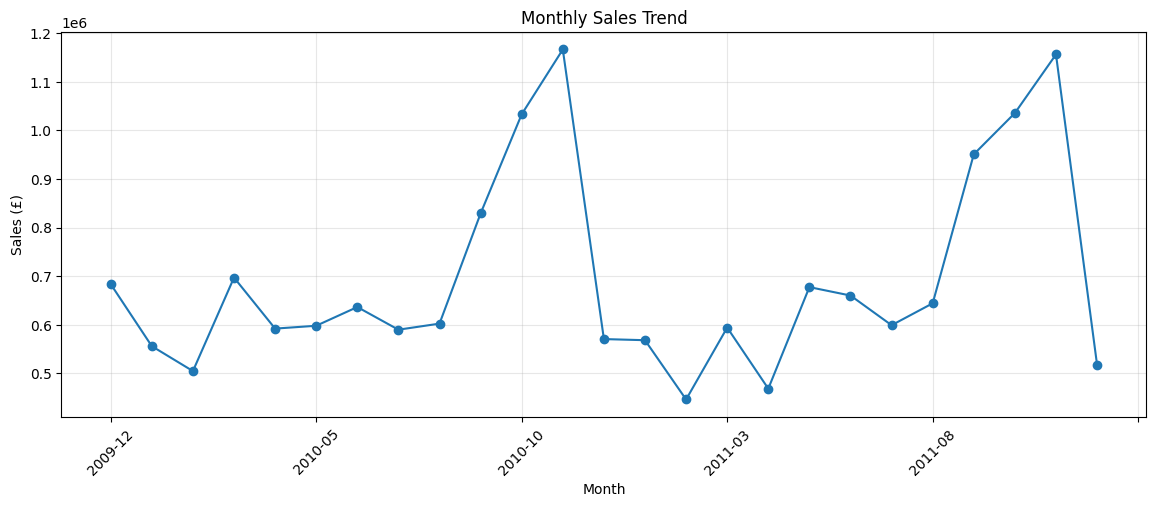

In [27]:
monthly_sales = df_clean.groupby(
    df_clean['InvoiceDate'].dt.to_period('M')
)['TotalPrice'].sum()

monthly_sales.index = monthly_sales.index.astype(str)

plt.figure(figsize=(14, 5))
monthly_sales.plot(marker='o')
plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Sales (£)')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.show()

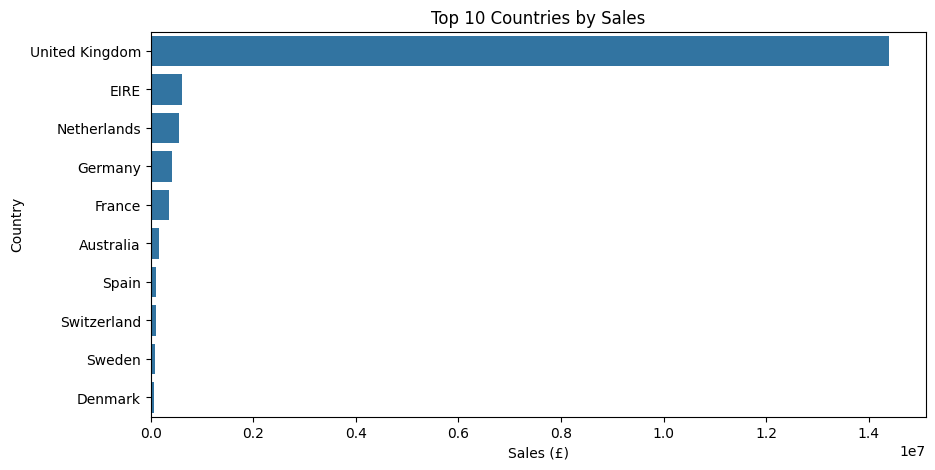

In [28]:
country_sales = df_clean.groupby('Country')['TotalPrice'].sum()

country_sales = country_sales.sort_values(
    ascending=False
).head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=country_sales.values, y=country_sales.index)
plt.title('Top 10 Countries by Sales')
plt.xlabel('Sales (£)')
plt.ylabel('Country')
plt.show()

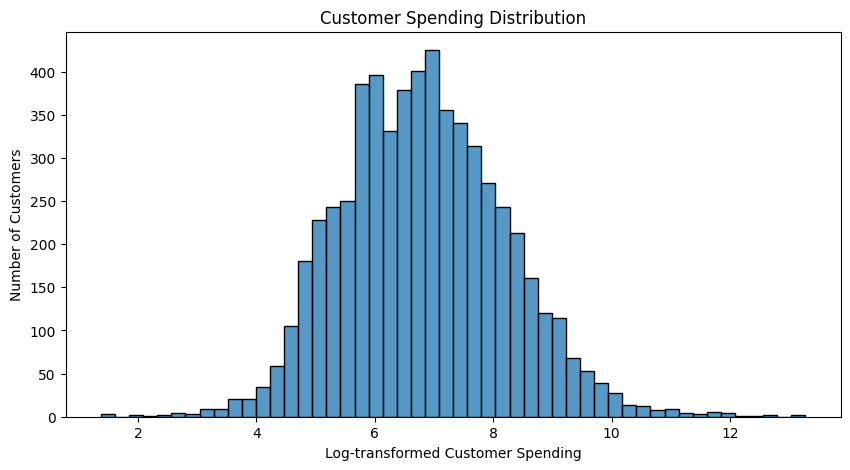

count      5878.000000
mean       2955.904095
std       14440.852688
min           2.950000
25%         342.280000
50%         867.740000
75%        2248.305000
max      580987.040000
Name: TotalPrice, dtype: float64

In [29]:
customer_spending = df_clean.groupby(
    'Customer ID'
)['TotalPrice'].sum()

plt.figure(figsize=(10, 5))
sns.histplot(np.log1p(customer_spending), bins=50)
plt.title('Customer Spending Distribution')
plt.xlabel('Log-transformed Customer Spending')
plt.ylabel('Number of Customers')
plt.show()

customer_spending.describe()

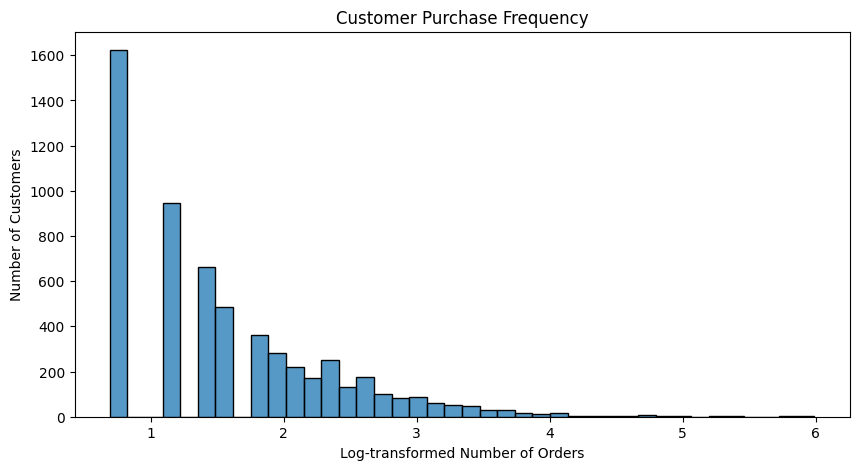

count    5878.000000
mean        6.289384
std        13.009406
min         1.000000
25%         1.000000
50%         3.000000
75%         7.000000
max       398.000000
Name: Invoice, dtype: float64

In [30]:
customer_frequency = df_clean.groupby(
    'Customer ID'
)['Invoice'].nunique()

plt.figure(figsize=(10, 5))
sns.histplot(np.log1p(customer_frequency), bins=40)
plt.title('Customer Purchase Frequency')
plt.xlabel('Log-transformed Number of Orders')
plt.ylabel('Number of Customers')
plt.show()

customer_frequency.describe()

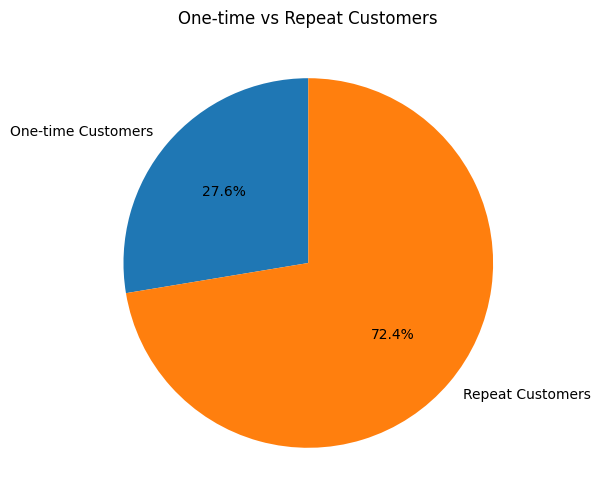

One-time Customers    1623
Repeat Customers      4255
dtype: int64


In [31]:
customer_type = pd.Series({
    'One-time Customers': (customer_frequency == 1).sum(),
    'Repeat Customers': (customer_frequency > 1).sum()
})

plt.figure(figsize=(6, 6))
plt.pie(
    customer_type.values,
    labels=customer_type.index,
    autopct='%1.1f%%',
    startangle=90
)
plt.title('One-time vs Repeat Customers')
plt.show()

print(customer_type)

# **RFM-Analysis**

In [34]:
reference_date = df_clean['InvoiceDate'].max().normalize() + pd.Timedelta(days=1)

print(reference_date)

2011-12-10 00:00:00


In [35]:
rfm = df_clean.groupby('Customer ID').agg(
    Recency=('InvoiceDate',
             lambda x: (reference_date - x.max().normalize()).days),

    Frequency=('Invoice', 'nunique'),

    Monetary=('TotalPrice', 'sum')
)

rfm.head()

,Recency,Frequency,Monetary
Customer ID,,,
12346,326,12,77556.46
12347,3,8,4921.53
12348,76,5,2019.40
12349,19,4,4428.69
12350,311,1,334.40


In [36]:
print("Shape:", rfm.shape)

rfm.describe()

Shape: (5878, 3)


,Recency,Frequency,Monetary
count,5878.000000,5878.000000,5878.000000
mean,201.866791,6.289384,2955.904095
std,209.353961,13.009406,14440.852688
min,1.000000,1.000000,2.950000
25%,26.000000,1.000000,342.280000
50%,96.000000,3.000000,867.740000
75%,380.000000,7.000000,2248.305000
max,739.000000,398.000000,580987.040000


In [37]:
rfm_log = np.log1p(rfm)

rfm_log.head()

,Recency,Frequency,Monetary
Customer ID,,,
12346,5.789960,2.564949,11.258774
12347,1.386294,2.197225,8.501578
12348,4.343805,1.791759,7.611051
12349,2.995732,1.609438,8.396085
12350,5.743003,0.693147,5.815324


In [38]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm_log)

rfm_scaled = pd.DataFrame(
    rfm_scaled,
    columns=rfm.columns,
    index=rfm.index
)

rfm_scaled.head()

,Recency,Frequency,Monetary
Customer ID,,,
12346,0.859687,1.254496,3.206219
12347,-2.017050,0.800166,1.215993
12348,-0.085028,0.299207,0.573185
12349,-0.965670,0.073946,1.139846
12350,0.829011,-1.058146,-0.723024


In [39]:
rfm_scaled.describe().round(3)

,Recency,Frequency,Monetary
count,5878.000,5878.000,5878.000
mean,0.000,0.000,0.000
std,1.000,1.000,1.000
min,-2.470,-1.058,-3.929
25%,-0.770,-1.058,-0.706
50%,0.066,-0.202,-0.036
75%,0.960,0.655,0.651
max,1.393,5.485,4.660


# **Customer Segmentation**

In [40]:
from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

In [41]:
wcss = []
silhouette_scores = []

k_values = range(2, 11)

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(rfm_scaled)

    wcss.append(kmeans.inertia_)

    silhouette_scores.append(
        silhouette_score(rfm_scaled, labels)
    )

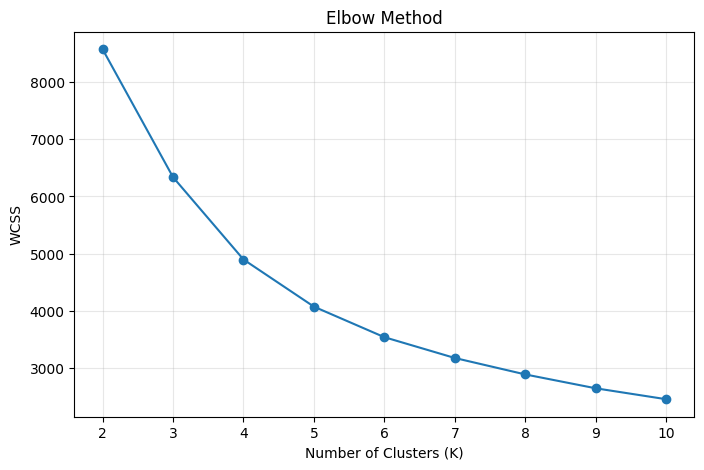

In [42]:
plt.figure(figsize=(8, 5))

plt.plot(k_values, wcss, marker='o')

plt.title('Elbow Method')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.xticks(list(k_values))
plt.grid(alpha=0.3)

plt.show()

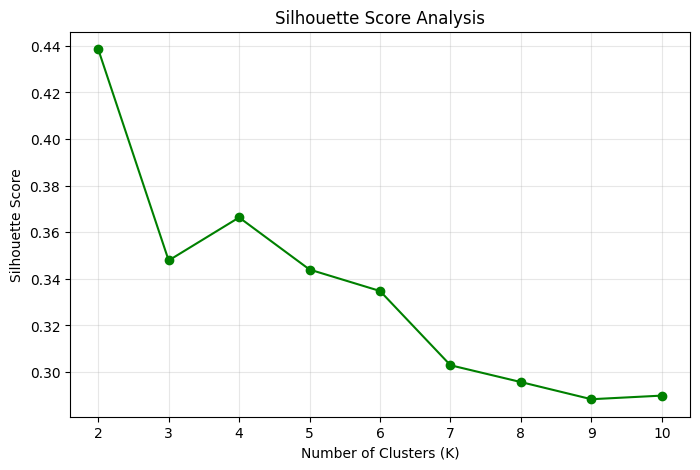

In [43]:
plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    silhouette_scores,
    marker='o',
    color='green'
)

plt.title('Silhouette Score Analysis')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.xticks(list(k_values))
plt.grid(alpha=0.3)

plt.show()

In [44]:
cluster_results = pd.DataFrame({
    'K': list(k_values),
    'WCSS': wcss,
    'Silhouette Score': silhouette_scores
})

cluster_results.round(4)

,K,WCSS,Silhouette Score
0,2,8577.1061,0.4385
1,3,6336.7921,0.3479
2,4,4895.4134,0.3664
3,5,4069.6259,0.3440
4,6,3535.1145,0.3348
5,7,3170.9200,0.3029
6,8,2883.1160,0.2957
7,9,2640.3988,0.2884
8,10,2449.2301,0.2899


In [45]:
best_k = cluster_results.loc[
    cluster_results['Silhouette Score'].idxmax(), 'K'
]

print("Best K based on Silhouette Score:", best_k)

Best K based on Silhouette Score: 2


# **K-Means_Clustering**

In [46]:
optimal_k = 4

kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

rfm['KMeans_Cluster'] = kmeans.fit_predict(rfm_scaled)

rfm.head()

,Recency,Frequency,Monetary,KMeans_Cluster
Customer ID,,,,
12346,326,12,77556.46,0
12347,3,8,4921.53,0
12348,76,5,2019.40,1
12349,19,4,4428.69,2
12350,311,1,334.40,3


In [47]:
hierarchical = AgglomerativeClustering(
    n_clusters=optimal_k,
    linkage='ward'
)

rfm['Hierarchical_Cluster'] = hierarchical.fit_predict(
    rfm_scaled
)

rfm.head()

,Recency,Frequency,Monetary,KMeans_Cluster,Hierarchical_Cluster
Customer ID,,,,,
12346,326,12,77556.46,0,1
12347,3,8,4921.53,0,0
12348,76,5,2019.40,1,2
12349,19,4,4428.69,2,2
12350,311,1,334.40,3,3


In [48]:
comparison = pd.DataFrame({
    'Model': ['K-Means', 'Hierarchical Clustering'],

    'Silhouette Score': [
        silhouette_score(
            rfm_scaled, rfm['KMeans_Cluster']
        ),
        silhouette_score(
            rfm_scaled, rfm['Hierarchical_Cluster']
        )
    ]
})

comparison.round(4)

,Model,Silhouette Score
0,K-Means,0.3664
1,Hierarchical Clustering,0.3179


In [49]:
kmeans_summary = rfm.groupby('KMeans_Cluster').agg(
    Customers=('Recency', 'size'),
    Avg_Recency=('Recency', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Monetary=('Monetary', 'mean'),
    Total_Spending=('Monetary', 'sum')
)

kmeans_summary.round(2)

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Total_Spending
KMeans_Cluster,,,,,
0,1204,28.44,19.21,10678.40,12856793.52
1,1455,231.20,5.03,1945.08,2830096.17
2,1261,29.24,3.03,847.75,1069014.65
3,1958,397.89,1.38,316.09,618899.93


In [50]:
hierarchical_summary = rfm.groupby(
    'Hierarchical_Cluster'
).agg(
    Customers=('Recency', 'size'),
    Avg_Recency=('Recency', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Monetary=('Monetary', 'mean'),
    Total_Spending=('Monetary', 'sum')
)

hierarchical_summary.round(2)

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Total_Spending
Hierarchical_Cluster,,,,,
0,1314,41.12,18.41,10070.14,13232159.21
1,1377,325.60,3.66,1481.63,2040200.27
2,1779,42.18,3.34,992.90,1766370.89
3,1408,432.63,1.28,238.69,336073.89


In [51]:
pca = PCA(n_components=2)

pca_features = pca.fit_transform(rfm_scaled)

rfm['PCA1'] = pca_features[:, 0]
rfm['PCA2'] = pca_features[:, 1]

print("Explained variance:",
      pca.explained_variance_ratio_.sum())

Explained variance: 0.9509854287679133


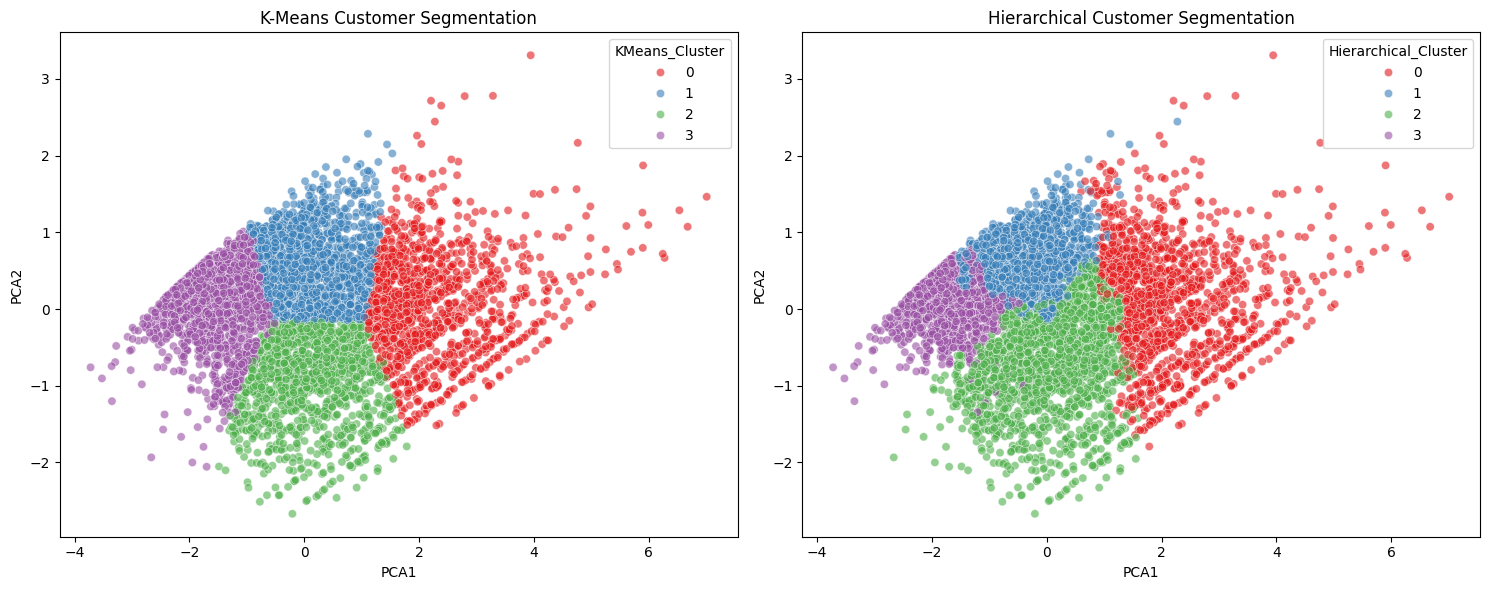

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.scatterplot(
    data=rfm,
    x='PCA1',
    y='PCA2',
    hue='KMeans_Cluster',
    palette='Set1',
    alpha=0.6,
    ax=axes[0]
)

axes[0].set_title('K-Means Customer Segmentation')

sns.scatterplot(
    data=rfm,
    x='PCA1',
    y='PCA2',
    hue='Hierarchical_Cluster',
    palette='Set1',
    alpha=0.6,
    ax=axes[1]
)

axes[1].set_title('Hierarchical Customer Segmentation')

plt.tight_layout()
plt.show()

In [53]:
segment_names = {
    0: 'High-Value Loyal',
    1: 'At-Risk',
    2: 'Active Occasional',
    3: 'Inactive Low-Value'
}

rfm['Segment'] = rfm['KMeans_Cluster'].map(segment_names)

rfm.head()

,Recency,Frequency,Monetary,KMeans_Cluster,Hierarchical_Cluster,PCA1,PCA2,Segment
Customer ID,,,,,,,,
12346,326,12,77556.46,0,1,2.275506,2.442792,High-Value Loyal
12347,3,8,4921.53,0,0,2.246181,-0.991572,High-Value Loyal
12348,76,5,2019.40,1,2,0.573559,0.253765,At-Risk
12349,19,4,4428.69,2,2,1.221335,-0.335379,Active Occasional
12350,311,1,334.40,3,3,-1.507872,0.097815,Inactive Low-Value


In [54]:
segment_summary = rfm.groupby('Segment').agg(
    Customers=('Recency', 'size'),
    Avg_Recency=('Recency', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Monetary=('Monetary', 'mean'),
    Total_Spending=('Monetary', 'sum')
)

segment_summary['Customer_Share (%)'] = (
    segment_summary['Customers'] / len(rfm) * 100
)

segment_summary['Sales_Share (%)'] = (
    segment_summary['Total_Spending'] /
    rfm['Monetary'].sum() * 100
)

segment_summary.round(2)

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Total_Spending,Customer_Share (%),Sales_Share (%)
Segment,,,,,,,
Active Occasional,1261,29.24,3.03,847.75,1069014.65,21.45,6.15
At-Risk,1455,231.20,5.03,1945.08,2830096.17,24.75,16.29
High-Value Loyal,1204,28.44,19.21,10678.40,12856793.52,20.48,74.00
Inactive Low-Value,1958,397.89,1.38,316.09,618899.93,33.31,3.56


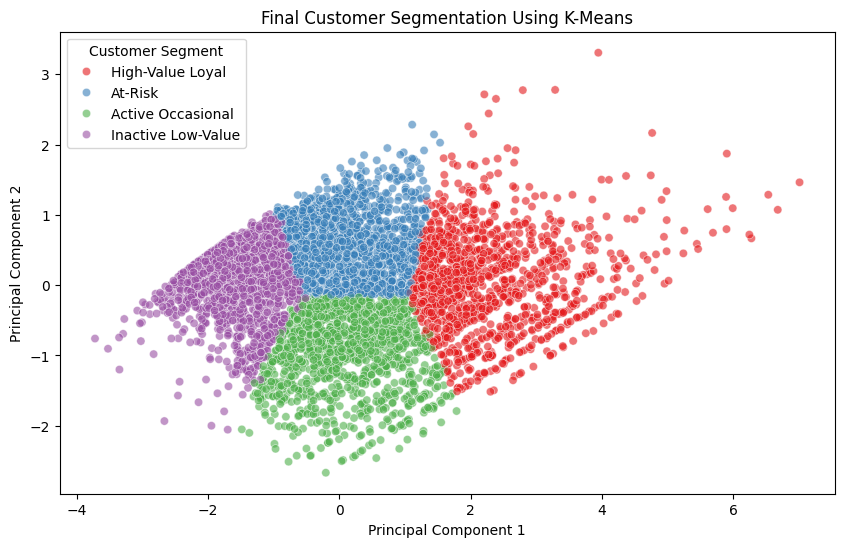

In [55]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=rfm,
    x='PCA1',
    y='PCA2',
    hue='Segment',
    palette='Set1',
    alpha=0.6
)

plt.title('Final Customer Segmentation Using K-Means')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Customer Segment')
plt.show()

# **Customer Churn Prediction**

In [56]:
def create_churn_dataset(data, cutoff_date):

    cutoff_date = pd.Timestamp(cutoff_date)
    end_date = cutoff_date + pd.Timedelta(days=90)

    historical = data[
        data['InvoiceDate'] < cutoff_date
    ]

    future = data[
        (data['InvoiceDate'] >= cutoff_date) &
        (data['InvoiceDate'] < end_date)
    ]

    features = historical.groupby('Customer ID').agg(
        Recency=('InvoiceDate',
                 lambda x: (cutoff_date - x.max().normalize()).days),

        Frequency=('Invoice', 'nunique'),

        Monetary=('TotalPrice', 'sum')
    )

    future_customers = future['Customer ID'].unique()

    features['Churn'] = (
        ~features.index.isin(future_customers)
    ).astype(int)

    return features

In [57]:
train_data = create_churn_dataset(
    df_clean, '2011-03-01'
)

test_data = create_churn_dataset(
    df_clean, '2011-09-01'
)

print("Training shape:", train_data.shape)
print("Testing shape:", test_data.shape)

train_data.head()

Training shape: (4537, 4)
Testing shape: (5249, 4)


,Recency,Frequency,Monetary,Churn
Customer ID,,,,
12346,42,12,77556.46,1
12347,34,3,1798.71,0
12348,35,3,1342.40,0
12349,124,3,2671.14,1
12350,27,1,334.40,1


In [58]:
print("Training distribution:")
print(train_data['Churn'].value_counts())

print("\nTesting distribution:")
print(test_data['Churn'].value_counts())

print("\nTraining churn percentage:")
print(train_data['Churn'].value_counts(normalize=True) * 100)

print("\nTesting churn percentage:")
print(test_data['Churn'].value_counts(normalize=True) * 100)

Training distribution:
Churn
1    2950
0    1587
Name: count, dtype: int64

Testing distribution:
Churn
1    3008
0    2241
Name: count, dtype: int64

Training churn percentage:
Churn
1    65.020939
0    34.979061
Name: proportion, dtype: float64

Testing churn percentage:
Churn
1    57.306154
0    42.693846
Name: proportion, dtype: float64


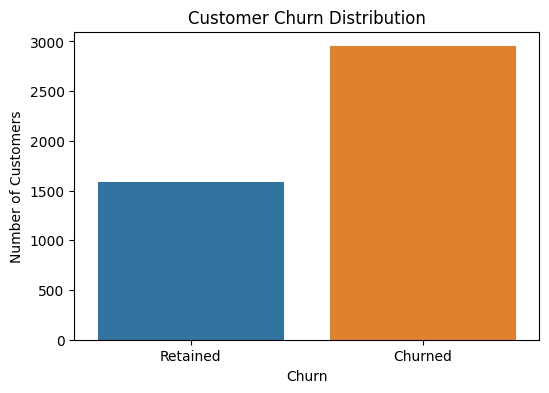

In [59]:
plt.figure(figsize=(6, 4))

sns.countplot(
    data=train_data,
    x='Churn',
    hue='Churn',
    legend=False
)

plt.xticks([0, 1], ['Retained', 'Churned'])
plt.title('Customer Churn Distribution')
plt.ylabel('Number of Customers')
plt.show()

In [60]:
X_train = train_data.drop(columns=['Churn'])
y_train = train_data['Churn']

X_test = test_data.drop(columns=['Churn'])
y_test = test_data['Churn']

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (4537, 3)
y_train: (4537,)
X_test: (5249, 3)
y_test: (5249,)


In [62]:
X_train_log = np.log1p(X_train)
X_test_log = np.log1p(X_test)

churn_scaler = StandardScaler()

X_train_scaled = churn_scaler.fit_transform(X_train_log)

X_test_scaled = churn_scaler.transform(X_test_log)

# **Model Training And Evaluation**

In [63]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

In [64]:
lr = LogisticRegression(
    random_state=42,
    max_iter=1000
)

lr.fit(X_train_scaled, y_train)

lr_pred = lr.predict(X_test_scaled)

lr_prob = lr.predict_proba(X_test_scaled)[:, 1]

In [65]:
rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=8,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

rf_prob = rf.predict_proba(X_test)[:, 1]

In [66]:
xgb = XGBClassifier(
    n_estimators=100,
    max_depth=4,
    learning_rate=0.05,
    random_state=42,
    eval_metric='logloss',
    n_jobs=-1
)

xgb.fit(X_train, y_train)

xgb_pred = xgb.predict(X_test)

xgb_prob = xgb.predict_proba(X_test)[:, 1]

In [67]:
def evaluate_model(name, y_true, y_pred, y_prob):

    return {
        'Model': name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1 Score': f1_score(y_true, y_pred),
        'ROC-AUC': roc_auc_score(y_true, y_prob),
        'PR-AUC (AP)': average_precision_score(y_true, y_prob)
    }

In [68]:
results = pd.DataFrame([
    evaluate_model(
        'Logistic Regression', y_test, lr_pred, lr_prob
    ),

    evaluate_model(
        'Random Forest', y_test, rf_pred, rf_prob
    ),

    evaluate_model(
        'XGBoost', y_test, xgb_pred, xgb_prob
    )
])

results.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC (AP)
0,Logistic Regression,0.7148,0.6969,0.8890,0.7813,0.7853,0.8170
1,Random Forest,0.7190,0.6963,0.9039,0.7866,0.7755,0.8020
2,XGBoost,0.7175,0.6953,0.9026,0.7855,0.7902,0.8186


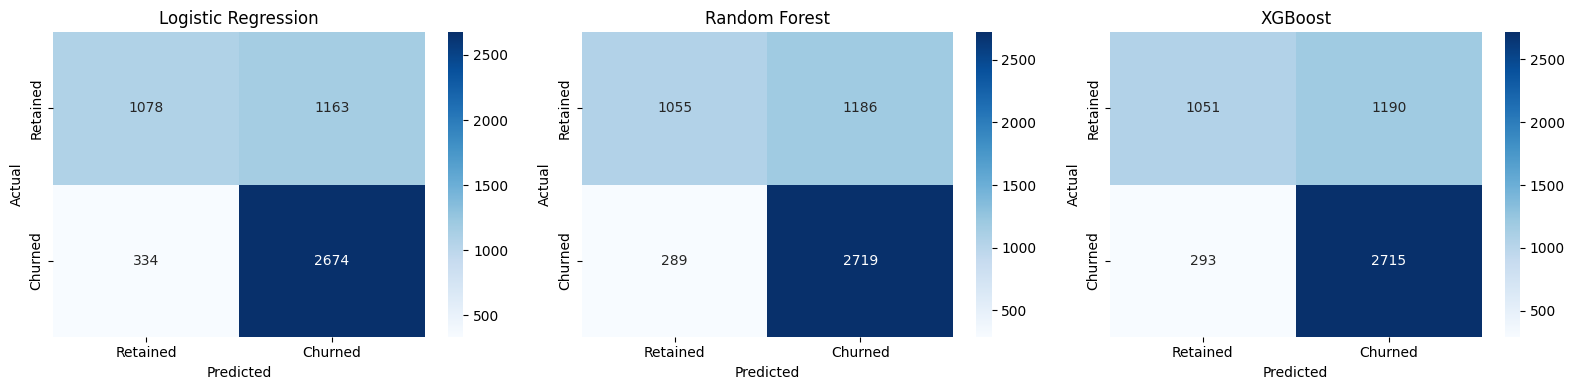

In [69]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

predictions = [lr_pred, rf_pred, xgb_pred]

names = ['Logistic Regression', 'Random Forest', 'XGBoost']

for ax, pred, name in zip(axes, predictions, names):

    sns.heatmap(
        confusion_matrix(y_test, pred),
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['Retained', 'Churned'],
        yticklabels=['Retained', 'Churned'],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()

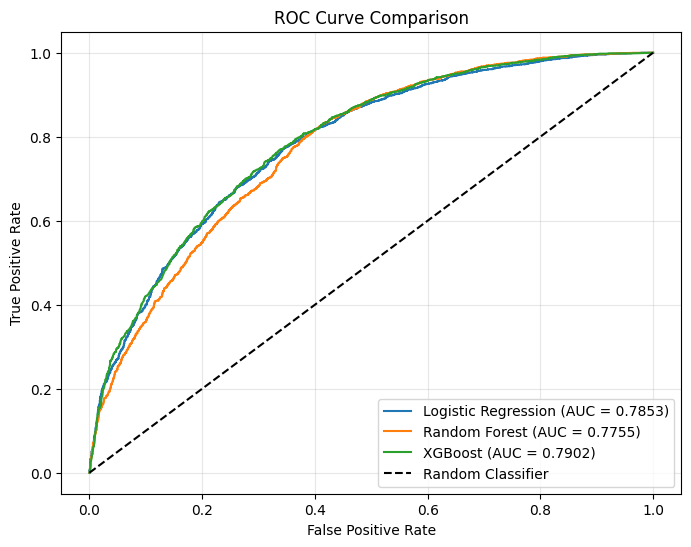

In [70]:
plt.figure(figsize=(8, 6))

probabilities = [lr_prob, rf_prob, xgb_prob]

for prob, name in zip(probabilities, names):

    fpr, tpr, _ = roc_curve(y_test, prob)

    auc = roc_auc_score(y_test, prob)

    plt.plot(
        fpr,
        tpr,
        label=f'{name} (AUC = {auc:.4f})'
    )

plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')

plt.title('ROC Curve Comparison')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# ** Explainable AI Using SHAP**

In [71]:
import shap

explainer = shap.TreeExplainer(xgb)

shap_values = explainer(X_test)

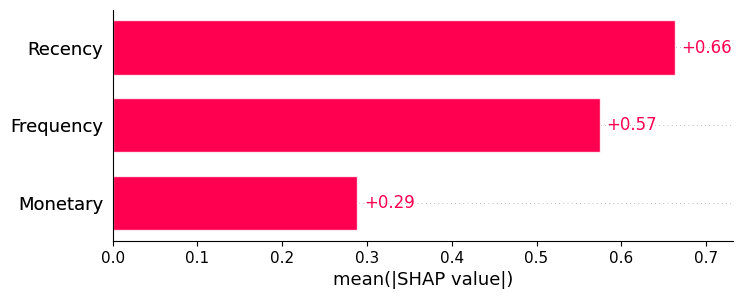

In [72]:
shap.plots.bar(shap_values)

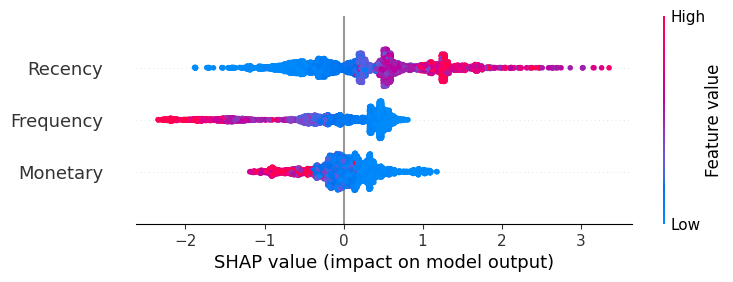

In [73]:
shap.plots.beeswarm(shap_values)

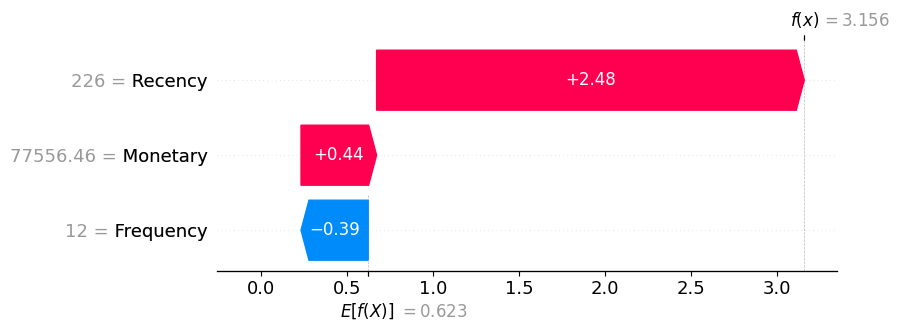

In [74]:
shap.plots.waterfall(shap_values[0])

In [75]:
print(X_test.iloc[0])

print("Actual Churn:", y_test.iloc[0])

print("Predicted Churn:", xgb_pred[0])

print("Estimated Churn Probability:", xgb_prob[0])

Recency        226.00
Frequency       12.00
Monetary     77556.46
Name: 12346, dtype: float64
Actual Churn: 1
Predicted Churn: 1
Estimated Churn Probability: 0.95914114


# Business Recommendations and Model Saving****

In [76]:
churn_report = X_test.copy()

churn_report['Actual_Churn'] = y_test
churn_report['Predicted_Churn'] = xgb_pred
churn_report['Churn_Probability'] = xgb_prob

churn_report = churn_report.sort_values(
    'Churn_Probability',
    ascending=False
)

churn_report.head(10)

,Recency,Frequency,Monetary,Actual_Churn,Predicted_Churn,Churn_Probability
Customer ID,,,,,,
14384,401,1,58.50,1,1,0.982519
17494,402,1,54.70,1,1,0.982519
14007,413,1,79.48,1,1,0.980613
13739,428,1,75.30,0,1,0.980613
17192,437,1,75.28,1,1,0.980613
16165,406,1,79.90,1,1,0.980613
14435,402,1,90.42,1,1,0.979785
12482,477,29,23691.40,1,1,0.979474
15040,442,1,7.49,1,1,0.979394


In [77]:
churn_report['Risk_Level'] = pd.cut(
    churn_report['Churn_Probability'],
    bins=[0, 0.5, 0.8, 1],
    labels=['Low Risk', 'Medium Risk', 'High Risk'],
    include_lowest=True,
    right=False
)

churn_report.loc[
    churn_report['Churn_Probability'] == 1,
    'Risk_Level'
] = 'High Risk'

churn_report.head(10)

,Recency,Frequency,Monetary,Actual_Churn,Predicted_Churn,Churn_Probability,Risk_Level
Customer ID,,,,,,,
14384,401,1,58.50,1,1,0.982519,High Risk
17494,402,1,54.70,1,1,0.982519,High Risk
14007,413,1,79.48,1,1,0.980613,High Risk
13739,428,1,75.30,0,1,0.980613,High Risk
17192,437,1,75.28,1,1,0.980613,High Risk
16165,406,1,79.90,1,1,0.980613,High Risk
14435,402,1,90.42,1,1,0.979785,High Risk
12482,477,29,23691.40,1,1,0.979474,High Risk
15040,442,1,7.49,1,1,0.979394,High Risk


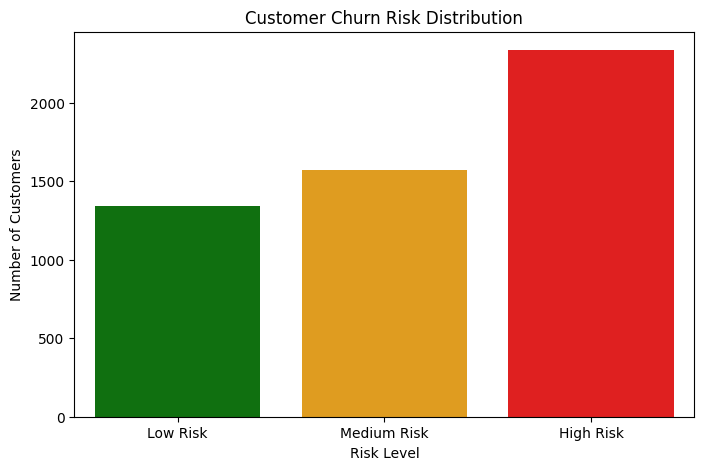

In [78]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=churn_report,
    x='Risk_Level',
    hue='Risk_Level',
    palette=['green', 'orange', 'red'],
    legend=False
)

plt.title('Customer Churn Risk Distribution')
plt.xlabel('Risk Level')
plt.ylabel('Number of Customers')
plt.show()

In [80]:
import joblib


joblib.dump(kmeans, 'kmeans_model.pkl')
joblib.dump(scaler, 'rfm_scaler.pkl')


xgb.save_model('xgboost_churn_model.json')


joblib.dump(segment_names, 'segment_names.pkl')


rfm.to_csv('customer_segments.csv')
churn_report.to_csv('churn_predictions.csv')


results.to_csv('model_comparison.csv', index=False)

print("Models and reports saved successfully.")

Models and reports saved successfully.


## Conclusion

This project developed an end-to-end customer intelligence system using the Online Retail II dataset. After data preprocessing, 779,425 transaction records representing 5,878 unique customers were retained for analysis.

### Customer Segmentation

RFM-based customer segmentation was performed using K-Means and Hierarchical Clustering. K-Means with four clusters achieved a Silhouette Score of 0.3664, outperforming the four-cluster Hierarchical Clustering model, which achieved 0.3179.

Four customer segments were identified: High-Value Loyal, At-Risk, Active Occasional and Inactive Low-Value. Approximately 20.5% of customers contributed 74% of retained sales, highlighting the business importance of retaining high-value customers.

### Customer Churn Prediction

Logistic Regression, Random Forest and XGBoost were evaluated using chronological training and testing periods. XGBoost achieved the highest ROC-AUC of 0.7902 and Average Precision of 0.8186, with an accuracy of 71.75%, recall of 90.26% and F1-score of 0.7855.

### Explainable AI

SHAP analysis identified Recency as the most influential feature, followed by Frequency and Monetary. The findings suggest that recent and frequent purchasing behavior is particularly important for identifying customers at risk of becoming inactive.

### Business Recommendations

- Provide loyalty rewards to high-value customers.
- Conduct personalized reactivation campaigns for at-risk customers.
- Encourage occasional customers to make repeat purchases.
- Prioritize retention campaigns using estimated churn risk.

### Limitations

Churn was defined as the absence of purchases within a 90-day period rather than permanent customer loss. The models were evaluated and compared using a single future test period. Additionally, the selected model generates a considerable number of false positives, and its probability estimates have not been independently calibrated.

Overall, the project demonstrates how classical machine learning and explainable AI can support customer segmentation, retention planning and data-driven business decision-making.

In [81]:
import zipfile

files = [
    'kmeans_model.pkl',
    'rfm_scaler.pkl',
    'segment_names.pkl',
    'xgboost_churn_model.json',
    'customer_segments.csv',
    'churn_predictions.csv',
    'model_comparison.csv'
]

with zipfile.ZipFile('project_files.zip', 'w') as z:
    for file in files:
        z.write(file)

print("ZIP file created successfully!")

ZIP file created successfully!


In [ ]:
from IPython.display import FileLink

FileLink('project_files.zip')